# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 8: PHÂN CỤM CHẨN ĐOÁN KHỐI U UNG THƯ VÚ WISCONSIN BẰNG K-MEANS
### (HỌC KHÔNG GIÁM SÁT TRONG PHÂN TÍCH TẾ BÀO HỌC Y KHOA: LÀNH TÍNH VÀ ÁC TÍNH)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score

print("Đã nạp đầy đủ các thư viện cần thiết cho Bài 8.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã nạp đầy đủ các thư viện cần thiết cho Bài 8.


### Câu a: Đọc bộ dữ liệu ung thư vú Wisconsin từ thư viện sklearn
Hướng dẫn: Sử dụng hàm `load_breast_cancer()` từ `sklearn.datasets` để nạp bộ dữ liệu 569 bệnh nhân với 30 thuộc tính đặc trưng tế bào học và nhãn chẩn đoán (Ác tính - Malignant / Lành tính - Benign).

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

print("Đã tải thành công bộ dữ liệu Breast Cancer Wisconsin.")
print(f"Số lượng mẫu bệnh nhân: {X.shape[0]}")
print(f"Số lượng thuộc tính hình thái tế bào: {X.shape[1]}")
print(f"Danh sách các nhãn chẩn đoán: {cancer.target_names.tolist()}")
print(f"Quy ước mã nhãn: 0 = {cancer.target_names[0]} (Ác tính), 1 = {cancer.target_names[1]} (Lành tính)")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đã tải thành công bộ dữ liệu Breast Cancer Wisconsin.
Số lượng mẫu bệnh nhân: 569
Số lượng thuộc tính hình thái tế bào: 30
Danh sách các nhãn chẩn đoán: ['malignant', 'benign']
Quy ước mã nhãn: 0 = malignant (Ác tính), 1 = benign (Lành tính)


### Câu b: Khảo sát cấu trúc và thống kê mô tả bộ dữ liệu
Hướng dẫn: Chuyển dữ liệu sang `pd.DataFrame`, in 5 mẫu đầu tiên, thống kê mô tả `describe()` và kiểm tra phân bố số lượng mẫu giữa hai lớp chẩn đoán.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
5 mẫu dữ liệu đầu tiên:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Thống kê số lượng từng loại khối u:
  - Khối u benign: 357 mẫu (62.74%)
  - Khối u malignant: 212 mẫu (37.26%)


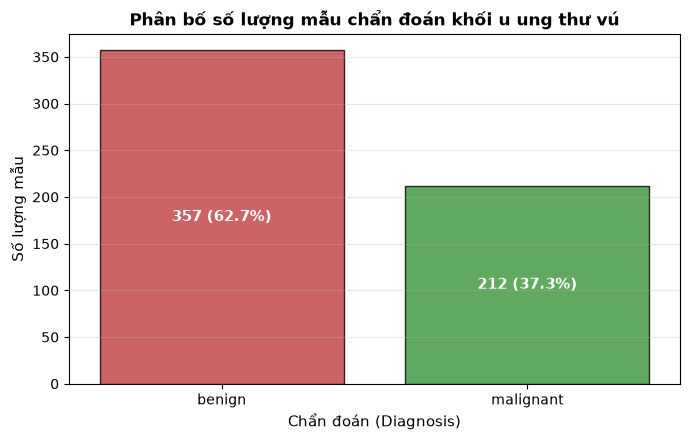

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

df_cancer = pd.DataFrame(X, columns=cancer.feature_names)
df_cancer['Diagnosis'] = y

print("5 mẫu dữ liệu đầu tiên:")
display(df_cancer.head())

print("\nThống kê số lượng từng loại khối u:")
counts = pd.Series(y).value_counts().rename({0: cancer.target_names[0], 1: cancer.target_names[1]})
for name, cnt in counts.items():
    print(f"  - Khối u {name}: {cnt} mẫu ({cnt / len(y) * 100:.2f}%)")

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=counts.index, y=counts.values, palette=['#d62728', '#2ca02c'], edgecolor='black', alpha=0.8)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(y)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.title('Phân bố số lượng mẫu chẩn đoán khối u ung thư vú', fontsize=12, fontweight='bold')
plt.xlabel('Chẩn đoán (Diagnosis)', fontsize=11)
plt.ylabel('Số lượng mẫu', fontsize=11)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Câu c: Chuẩn hóa dữ liệu bằng StandardScaler
Hướng dẫn: Vì 30 thuộc tính tế bào học có thang đo và đơn vị rất khác nhau (diện tích, độ nhẵn, chu vi,...), cần chuẩn hóa về phân phối chuẩn $z = \frac{x - \mu}{\sigma}$ để các thuộc tính đóng góp công bằng vào khoảng cách Euclidean trong thuật toán K-Means.

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Đã hoàn tất chuẩn hóa dữ liệu bằng StandardScaler.")
print(f"Giá trị trung bình sau chuẩn hóa (gần bằng 0): {np.mean(X_scaled):.4f}")
print(f"Độ lệch chuẩn sau chuẩn hóa (gần bằng 1):    {np.std(X_scaled):.4f}")
print(f"Kích thước ma trận sau chuẩn hóa:          {X_scaled.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã hoàn tất chuẩn hóa dữ liệu bằng StandardScaler.
Giá trị trung bình sau chuẩn hóa (gần bằng 0): -0.0000
Độ lệch chuẩn sau chuẩn hóa (gần bằng 1):    1.0000
Kích thước ma trận sau chuẩn hóa:          (569, 30)


### Câu d: Gom cụm bằng thuật toán K-Means với 2 cụm (k = 2)
Hướng dẫn: Áp dụng `KMeans(n_clusters=2, random_state=42)` trên ma trận dữ liệu đã chuẩn hóa.

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

kmeans_cancer = KMeans(n_clusters=2, init='k-means++', n_init=10, max_iter=300, random_state=42)
cluster_labels = kmeans_cancer.fit_predict(X_scaled)

print("Đã thực hiện gom cụm dữ liệu ung thư vú thành 2 cụm.")
print(f"Tổng bình phương sai số trong cụm (Inertia): {kmeans_cancer.inertia_:.2f}")
print(f"Số lượng mẫu trong Cụm 0: {(cluster_labels == 0).sum()} mẫu")
print(f"Số lượng mẫu trong Cụm 1: {(cluster_labels == 1).sum()} mẫu")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã thực hiện gom cụm dữ liệu ung thư vú thành 2 cụm.
Tổng bình phương sai số trong cụm (Inertia): 11595.53
Số lượng mẫu trong Cụm 0: 375 mẫu
Số lượng mẫu trong Cụm 1: 194 mẫu


### Câu e: So khớp và ánh xạ cụm tìm được với nhãn chẩn đoán thực tế
Hướng dẫn: Sử dụng phương pháp Majority Voting để xác định cụm nào tương ứng với khối u Lành tính (Benign) và cụm nào tương ứng với Ác tính (Malignant).

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print("Phân bố nhãn thực tế bên trong từng cụm:")
print("-" * 70)
print(f"{'Cụm (Cluster)':^15} | {'Ác tính (Malignant: 0)':^22} | {'Lành tính (Benign: 1)':^22}")
print("-" * 70)

cluster_mapping = {}
for c in [0, 1]:
    mask = (cluster_labels == c)
    mal_count = (y[mask] == 0).sum()
    ben_count = (y[mask] == 1).sum()
    assigned = 1 if ben_count > mal_count else 0
    assigned_name = cancer.target_names[assigned]
    cluster_mapping[c] = assigned

    print(f"{c:^15d} | {mal_count:^22d} | {ben_count:^22d} -> Gán là: {assigned_name} (ID: {assigned})")

print("-" * 70)
print(f"Quy tắc ánh xạ (Cluster ID -> True Label ID): {cluster_mapping}")

# Tạo mảng nhãn dự đoán sau ánh xạ
y_pred_mapped = np.array([cluster_mapping[c] for c in cluster_labels])

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Phân bố nhãn thực tế bên trong từng cụm:
----------------------------------------------------------------------
 Cụm (Cluster)  | Ác tính (Malignant: 0) | Lành tính (Benign: 1) 
----------------------------------------------------------------------
       0        |           36           |          339           -> Gán là: benign (ID: 1)
       1        |          176           |           18           -> Gán là: malignant (ID: 0)
----------------------------------------------------------------------
Quy tắc ánh xạ (Cluster ID -> True Label ID): {0: 1, 1: 0}
